# 06 · Execution risk and research reflections

As Avellaneda and Stoikov (2008) explain in *High-frequency trading in a limit order book*, inventory and execution considerations matter when managing limit orders. The present study does not estimate their model. Its execution experiment instead makes a simple, inspectable assumption: each basket leg fills independently with a chosen probability, while unfilled legs leave the acquired positions exposed.

This synthetic experiment illustrates why a favourable basket quote is insufficient to guarantee the portfolio will be acquired.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'kalshi_engine/client.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from kalshi_engine.client import ROOT
from kalshi_engine.presentation import show_table, show_figure, equation, read
from kalshi_engine.microstructure import Book, FeePolicy, sweep, execution_fee
from kalshi_engine.arbitrage import partition_audit, temperature_payoff_states, coherence, basket, statewise_portfolio
from kalshi_engine.probability import normalise, calibrate, scores, fit_temperature, paired_block_interval
print('Kalshi Microstructure Research | recorded public-data study | no order placement')

Kalshi Microstructure Research | recorded public-data study | no order placement


\Pr(\mathrm{all\ legs\ fill})=\rho^K (18)

per_leg_fill_probability,all_six_fill_probability
0.50000,0.01562
0.70000,0.11765
0.85000,0.37715
0.95000,0.73509
1.00000,1.00000


fill_probability,all_leg_fill_rate,loss_rate,mean_pnl,p05
0.50000,0.01460,0.48455,0.02359,-0.63570
0.70000,0.11680,0.29635,0.03625,-0.63570
0.85000,0.37235,0.15190,0.03911,-0.79462
0.95000,0.73055,0.05140,0.04341,-0.63570
1.00000,1.00000,0.00000,0.04645,0.04645


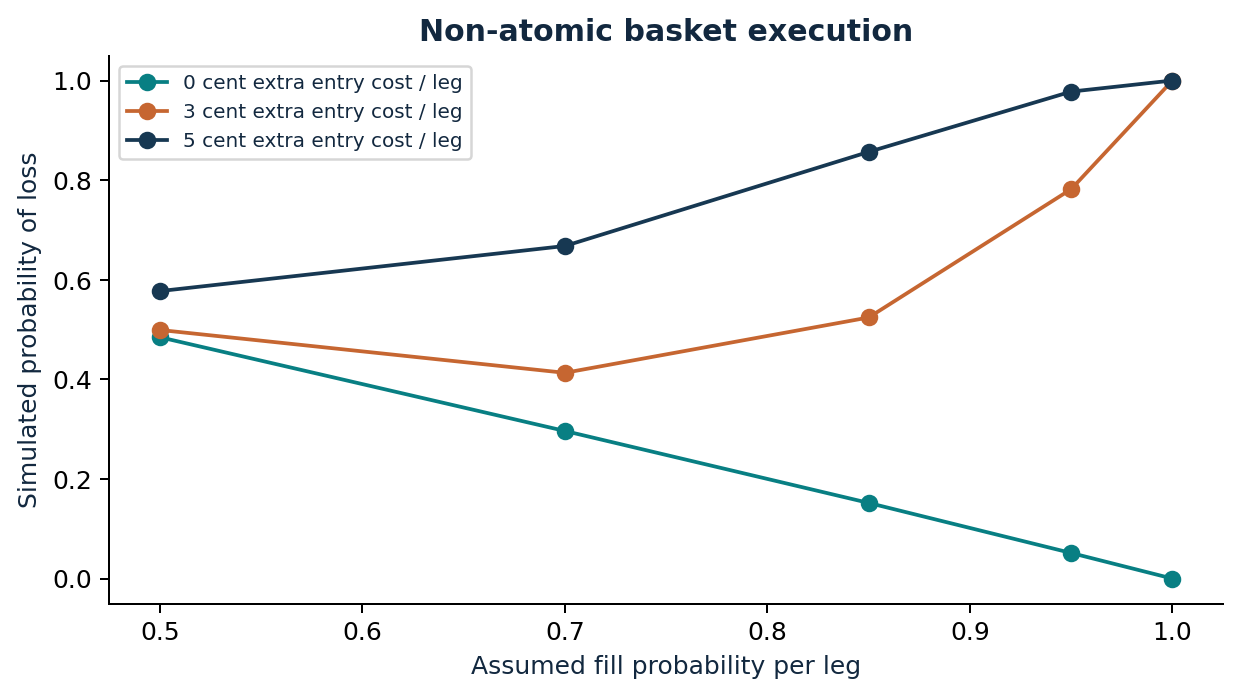

Figure 9. Synthetic independent leg-fill stresses. A positive expected payoff can coexist with losses when an incomplete basket remains exposed.

In [2]:
equation(18)
n=6
show_table(pd.DataFrame([{'per_leg_fill_probability':r,'all_six_fill_probability':r**n} for r in [.5,.7,.85,.95,1]]), 'Table N06.1. Synthetic all-leg completion under independent fills.')
stress=pd.read_csv(ROOT/'outputs/tables/execution-stress.csv')
show_table(stress[np.isclose(stress.adverse_entry_cost,0)][['fill_probability','all_leg_fill_rate','loss_rate','mean_pnl','p05']], 'Table N06.2. Simulated incomplete-basket outcomes at the original entry prices.')
show_figure(9)

## What did not work, and why

The first candle-batch size failed because the API caps the potential grid, not just nonempty rows. Smaller batches repaired acquisition. Archived and current schemas differed, requiring explicit adapters. One manifest index entry was lost during concurrent writes; the raw snapshot was intact and the recovered file-hash index verifies the complete cache.

Rounded bucket labels failed as an unconditional proof of exhaustiveness: the written terms use full source precision. The payoff-state matrix now retains fractional-temperature gaps, while fair-value fallback remains unresolved. Faster HTTP polling would not remove either contractual issue.

Temperature scaling improved development fit but failed validation. The baseline was retained. The live session was too short and lacked queue information, so fill probabilities remain synthetic. None of these issues is hidden by reporting a profitable backtest.

In [3]:
supp=read('outputs/supplementary-results.json')
show_table(pd.DataFrame([{'issue':'Manifest indexing','finding':str(supp['parallel_manifest_missing_entries'])+' recovered missing entry; stored snapshots verified'},{'issue':'Full-precision exhaustiveness','finding':str(supp['continuous_partition_events'])+' events passed the strict partition condition'},{'issue':'Calibration selection','finding':'Baseline selected before test scoring'},{'issue':'Execution','finding':'No empirical fill probability; hypothetical stresses only'},{'issue':'Public release','finding':'API-data permissions remain unresolved'}]), 'Table N06.3. Actual failures, mitigations and remaining limits.')

issue,finding
Manifest indexing,1 recovered missing entry; stored snapshots verified
Full-precision exhaustiveness,0 events passed the strict partition condition
Calibration selection,Baseline selected before test scoring
Execution,No empirical fill probability; hypothetical stresses only
Public release,API-data permissions remain unresolved


## A stronger next experiment

A prospective sample would freeze the scanner before collecting a longer, representative sequence, retain exchange-timestamped updates where access is permitted, and record settlement-rule versions. An external forecast must have a verified publication time and compatible settlement target. Each improvement addresses a different identification problem; a more flexible statistical model cannot replace missing execution evidence.

In [4]:
results=read('outputs/probability-results.json')
show_table(pd.DataFrame(results['city_scores']), 'Table N06.4. Later-period noon scores by city; descriptive subgroup comparison.')
print('Additional hours and block lengths are sensitivity analyses, not additional independent successes.')

series,model,log_loss,brier
KXHIGHCHI,baseline,0.84700,0.43956
KXHIGHCHI,calibrated,0.84700,0.43956
KXHIGHCHI,candidate,0.84749,0.44099
KXHIGHMIA,baseline,0.66984,0.37548
KXHIGHMIA,calibrated,0.66984,0.37548
KXHIGHMIA,candidate,0.67282,0.37642
KXHIGHNY,baseline,0.64606,0.41152
KXHIGHNY,calibrated,0.64606,0.41152
KXHIGHNY,candidate,0.65311,0.41242


Additional hours and block lengths are sensitivity analyses, not additional independent successes.
